# Рекомендательная система фильмов

Данные: MovieLens — 100 836 оценок, 610 пользователей, 9 742 фильма, постеры и описания из TMDB.

Что делаем:
1. смотрим на данные;
2. обучаем модель — три подхода: **популярность**, **SVD** (по оценкам), **контент** (жанры + описание);
3. объединяем их в гибрид и проверяем качество (Precision@10 / Recall@10);
4. сохраняем модель в отдельный файл.

Сам код модели лежит в **`recommender.py`** — ноутбук только вызывает его.

## 1. Данные

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recommender import Recommender

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 50)

movies = pd.read_csv("movies.csv")
ratings = pd.read_csv("ratings (1).csv")
photo = pd.read_csv("photo.csv")

print("фильмов:", len(movies), "| оценок:", len(ratings), "| пользователей:", ratings.userId.nunique())
print("заполненность матрицы: {:.2%}".format(len(ratings) / (ratings.userId.nunique() * ratings.movieId.nunique())))
movies[["movieId", "title", "year", "genres"]].astype({"year": "Int64"}).head()

фильмов: 9742 | оценок: 100836 | пользователей: 610
заполненность матрицы: 1.70%


,movieId,title,year,genres
0,1,Toy Story (1995),1995,Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),1995,Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),1995,Comedy|Romance
3,4,Waiting to Exhale (1995),1995,Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),1995,Comedy


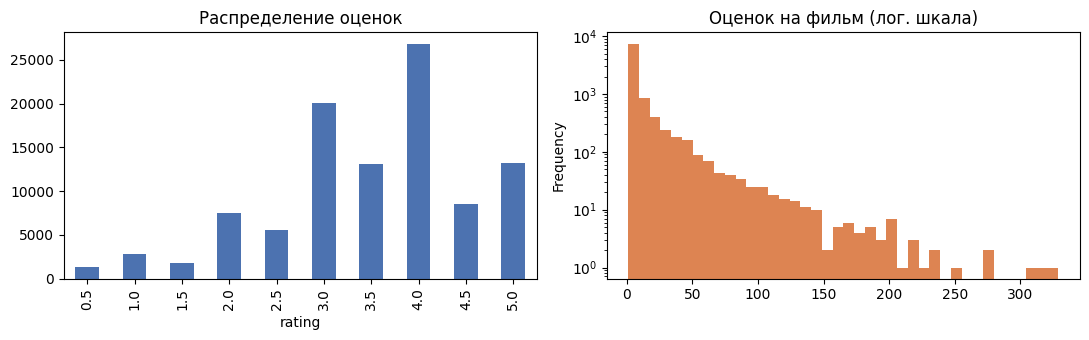

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="#4c72b0")
ax[0].set_title("Распределение оценок")
ratings.groupby("movieId").size().plot.hist(bins=40, log=True, ax=ax[1], color="#dd8452")
ax[1].set_title("Оценок на фильм (лог. шкала)")
plt.tight_layout()
plt.show()

Матрица заполнена меньше чем на 2 %, а у большинства фильмов совсем мало оценок. Поэтому фильмы с малым числом голосов в рекомендации не попадают (порог — 20 оценок).

## 2. Обучение модели

Класс `Recommender` делает следующее:
- **популярность** — взвешенный рейтинг IMDb: `(v·R + m·C) / (v + m)`, чтобы фильм с одной пятёркой не обгонял фильм с тысячей оценок;
- **SVD** — оценки пользователей (за вычетом его среднего) раскладываются на 40 скрытых факторов; по ним считается и сходство фильмов, и баллы для пользователя;
- **контент** — TF-IDF по жанрам и описанию фильма; профиль вкуса = средний вектор фильмов, которые пользователь оценил на 4 и выше;
- **гибрид** = 0.7 · SVD + 0.3 · контент.

In [3]:
model = Recommender(n_factors=40, alpha=0.7, min_votes=20).fit(movies, ratings, photo)
model.popular(10)[["title", "genres", "votes", "score"]]

,title,genres,votes,score
0,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.337
1,"Godfather, The (1972)",Crime|Drama,192,4.162
2,Fight Club (1999),Action|Crime|Drama|Thriller,218,4.162
3,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251,4.137
4,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,204,4.124
5,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.122
6,Schindler's List (1993),Drama|War,220,4.120
7,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.110
8,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,211,4.108
9,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.096


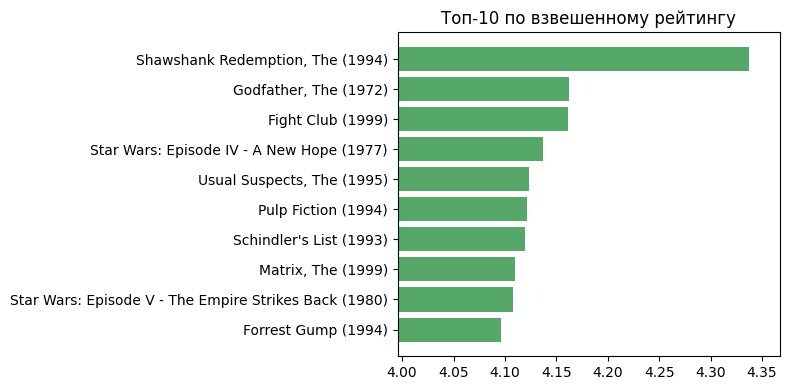

In [4]:
top = model.popular(10)
plt.figure(figsize=(8, 4))
plt.barh(top.title[::-1], top.score[::-1], color="#55a868")
plt.xlim(top.score.min() - 0.1, top.score.max() + 0.03)
plt.title("Топ-10 по взвешенному рейтингу")
plt.tight_layout()
plt.show()

In [5]:
model.popular(5, genre="Comedy")[["title", "votes", "score"]]

,title,votes,score
0,Pulp Fiction (1994),307,4.122
1,Forrest Gump (1994),329,4.096
2,"Princess Bride, The (1987)",142,4.077
3,Dr. Strangelove or: How I Learned to Stop Worr...,97,4.049
4,"Amelie (Fabuleux destin d'Amélie Poulain, Le) ...",120,4.014


## 3. Похожие фильмы

In [6]:
# по оценкам пользователей (SVD)
model.similar("Toy Story (1995)", 10, by="svd")[["title", "genres", "similarity"]]

,title,genres,similarity
0,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.594
1,Back to the Future (1985),Adventure|Comedy|Sci-Fi,0.479
2,Blazing Saddles (1974),Comedy|Western,0.452
3,Babe (1995),Children|Drama,0.439
4,"Incredibles, The (2004)",Action|Adventure|Animation|Children|Comedy,0.437
5,Beauty and the Beast (1991),Animation|Children|Fantasy|Musical|Romance|IMAX,0.435
6,Wallace & Gromit: The Wrong Trousers (1993),Animation|Children|Comedy|Crime,0.432
7,Love Actually (2003),Comedy|Drama|Romance,0.419
8,Ghostbusters (a.k.a. Ghost Busters) (1984),Action|Comedy|Sci-Fi,0.404
9,Billy Elliot (2000),Drama,0.404


In [7]:
# по жанрам и описанию (контент)
model.similar("Matrix, The", 10, by="content")[["title", "genres", "similarity"]]

,title,genres,similarity
0,Hackers (1995),Action|Adventure|Crime|Thriller,0.199
1,"Animatrix, The (2003)",Action|Animation|Drama|Sci-Fi,0.169
2,Avatar (2009),Action|Adventure|Sci-Fi|IMAX,0.157
3,Live Free or Die Hard (2007),Action|Adventure|Crime|Thriller,0.151
4,"Lawnmower Man, The (1992)",Action|Horror|Sci-Fi|Thriller,0.128
5,"Matrix Reloaded, The (2003)",Action|Adventure|Sci-Fi|Thriller|IMAX,0.123
6,Rocky III (1982),Action|Drama,0.119
7,Little Big Man (1970),Western,0.116
8,WarGames (1983),Drama|Sci-Fi|Thriller,0.114
9,Mad Max: Fury Road (2015),Action|Adventure|Sci-Fi|Thriller,0.111


## 4. Персональные рекомендации

In [8]:
user = 1
fav = ratings[ratings.userId == user].nlargest(8, "rating").merge(movies, on="movieId")
fav[["title", "genres", "rating"]]

,title,genres,rating
0,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,5.000
1,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.000
2,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance,5.000
3,Rob Roy (1995),Action|Drama|Romance|War,5.000
4,Canadian Bacon (1995),Comedy|War,5.000
5,Desperado (1995),Action|Romance|Western,5.000
6,Billy Madison (1995),Comedy,5.000
7,Dumb & Dumber (Dumb and Dumber) (1994),Adventure|Comedy,5.000


In [9]:
model.recommend_user(user, 10)[["title", "genres", "score"]]

,title,genres,score
0,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi,0.678
1,Blade Runner (1982),Action|Sci-Fi|Thriller,0.674
2,Gattaca (1997),Drama|Sci-Fi|Thriller,0.648
3,North by Northwest (1959),Action|Adventure|Mystery|Romance|Thriller,0.638
4,Mary Poppins (1964),Children|Comedy|Fantasy|Musical,0.637
5,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy,0.616
6,"Little Mermaid, The (1989)",Animation|Children|Comedy|Musical|Romance,0.612
7,"Sound of Music, The (1965)",Musical|Romance,0.589
8,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,0.587
9,"City of Lost Children, The (Cité des enfants p...",Adventure|Drama|Fantasy|Mystery|Sci-Fi,0.585


Новый пользователь: достаточно нескольких оценок — модель «складывает» его в то же SVD-пространство, переобучать ничего не нужно.

In [10]:
new_user = {
    model.find("Matrix, The"): 5,
    model.find("Inception"): 5,
    model.find("Interstellar"): 4.5,
    model.find("Titanic (1997)"): 2,
}
model.recommend(new_user, 10)[["title", "genres", "score"]]

,title,genres,score
0,Fight Club (1999),Action|Crime|Drama|Thriller,0.492
1,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,0.485
2,Memento (2000),Mystery|Thriller,0.474
3,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,0.450
4,"South Park: Bigger, Longer and Uncut (1999)",Animation|Comedy|Musical,0.447
5,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,0.446
6,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,0.444
7,Die Hard (1988),Action|Crime|Thriller,0.435
8,Gattaca (1997),Drama|Sci-Fi|Thriller,0.433
9,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,0.430


## 5. Проверка качества

Для каждого пользователя прячем 20 % его хороших оценок (≥ 4). Модель переобучается на остальном и строит топ-10 — смотрим, сколько спрятанных фильмов она угадала.
- **Precision@10** — доля угаданных среди 10 рекомендаций;
- **Recall@10** — доля найденных из спрятанных.

Базовый уровень — «всем одинаковый топ популярных».

In [11]:
good = ratings[ratings.rating >= 4]
test_idx = good.groupby("userId", group_keys=False).apply(
    lambda g: g.sample(frac=0.2, random_state=42) if len(g) >= 5 else g.iloc[0:0]).index
train, test = ratings.drop(test_idx), ratings.loc[test_idx]

m_eval = Recommender().fit(movies, train, photo)
train_by_user = train.groupby("userId").apply(lambda g: dict(zip(g.movieId, g.rating)))


def evaluate(score_fn, k=10):
    P, R = [], []
    for u, g in test.groupby("userId"):
        seen = train_by_user[u]
        s = score_fn(seen).copy()
        s[~m_eval.ok] = -np.inf
        for mid in seen:
            s[m_eval.pos[mid]] = -np.inf
        top = m_eval.movies.index[np.argsort(-s)[:k]]
        hits = len(set(top) & set(g.movieId))
        P.append(hits / k)
        R.append(hits / len(g))
    return {"Precision@10": np.mean(P), "Recall@10": np.mean(R)}


results = pd.DataFrame({
    "Популярные":      evaluate(lambda s: m_eval.movies.score.values),
    "SVD":             evaluate(lambda s: m_eval.scores(s, alpha=1.0)),
    "Контент":         evaluate(lambda s: m_eval.scores(s, alpha=0.0)),
    "Гибрид (0.7/0.3)": evaluate(lambda s: m_eval.scores(s, alpha=0.7)),
}).T
results

,Precision@10,Recall@10
Популярные,0.117,0.100
SVD,0.136,0.118
Контент,0.037,0.037
Гибрид (0.7/0.3),0.143,0.129


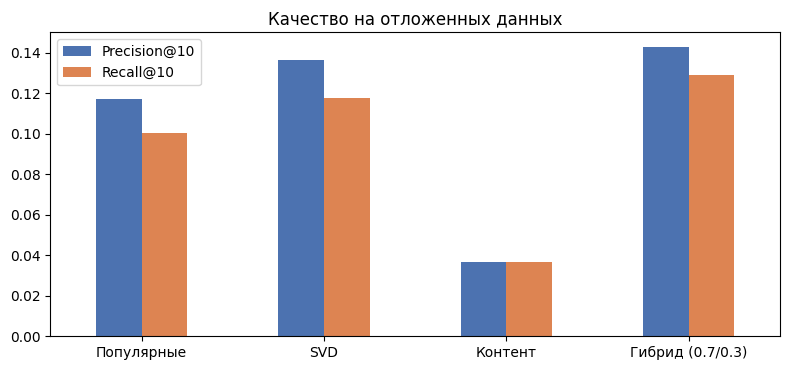

In [12]:
results.plot.bar(figsize=(8, 3.8), rot=0, color=["#4c72b0", "#dd8452"])
plt.title("Качество на отложенных данных")
plt.tight_layout()
plt.show()

## 6. Сохранение модели

In [13]:
final = Recommender(n_factors=40, alpha=0.7, min_votes=20).fit(movies, ratings, photo)
final.save("recommender.pkl")

# проверка: загружаем из файла и получаем рекомендации
loaded = Recommender.load("recommender.pkl")
loaded.recommend({loaded.find("Toy Story (1995)"): 5, loaded.find("Lion King, The"): 5}, 5)[["title", "genres", "score"]]

,title,genres,score
0,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.171
1,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.145
2,"40-Year-Old Virgin, The (2005)",Comedy|Romance,0.094
3,Man on the Moon (1999),Comedy|Drama,0.049
4,"Little Mermaid, The (1989)",Animation|Children|Comedy|Musical|Romance,0.041


## Выводы

- Любая персонализированная модель лучше общего топа популярных: SVD заметно обгоняет базовый уровень.
- Одни только жанры и описание рекомендуют слабо, но в паре с SVD дают прирост — гибрид показал лучший результат.
- Модель работает для нового пользователя после нескольких оценок, а популярный топ остаётся запасным вариантом, если оценок нет совсем.
- Для API хватает пяти методов: `popular`, `similar`, `recommend`, `recommend_user`, `find` — файл `recommender.pkl` загружается одной строкой.